# Hypothesis Testing in Healthcare: Drug Safety

A pharmaceutical company GlobalXYZ has just completed a randomized controlled drug trial. To promote transparency and reproducibility of the drug's outcome, they (GlobalXYZ) have presented the dataset to your organization, a non-profit that focuses primarily on drug safety.

The dataset provided contained five adverse effects, demographic data, vital signs, etc. Your organization is primarily interested in the drug's adverse reactions. It wants to know if the adverse reactions, if any, are of significant proportions. It has asked you to explore and answer some questions from the data.

The dataset `drug_safety.csv` was obtained from [Hbiostat](https://hbiostat.org/data/) courtesy of the Vanderbilt University Department of Biostatistics. It contained five adverse effects: headache, abdominal pain, dyspepsia, upper respiratory infection, chronic obstructive airway disease (COAD), demographic data, vital signs, lab measures, etc. The ratio of drug observations to placebo observations is 2 to 1.

For this project, the dataset has been modified to reflect the presence and absence of adverse effects `adverse_effects` and the number of adverse effects in a single individual `num_effects`.

The columns in the modified dataset are: 

| Column | Description |
|--------|-------------|
|`sex` | The gender of the individual |
|`age` | The age of the individual |
|`week` | The week of the drug testing |
|`trx` | The treatment (Drug) and control (Placebo) groups | 
|`wbc` | The count of white blood cells |
|`rbc` | The count of red blood cells |
|`adverse_effects` | The presence of at least a single adverse effect |
|`num_effects` | The number of adverse effects experienced by a single individual |

The original dataset can be found [here](https://hbiostat.org/data/repo/safety.rda).

Your organization has asked you to explore and answer some questions from the data collected. See the project instructions.

In [1]:
# Import packages
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest
import pingouin
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
drug_safety = pd.read_csv("drug_safety.csv")

# Start coding here...
drug_safety.describe()

drug_safety.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16103 entries, 0 to 16102
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              16103 non-null  int64  
 1   sex              16103 non-null  object 
 2   trx              16103 non-null  object 
 3   week             16103 non-null  int64  
 4   wbc              9128 non-null   float64
 5   rbc              9127 non-null   float64
 6   adverse_effects  16103 non-null  object 
 7   num_effects      16103 non-null  int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 1006.6+ KB


In [2]:
drug_safety.head(100)


,age,sex,trx,week,wbc,rbc,adverse_effects,num_effects
0,62,male,Drug,0,7.3,5.1,No,0
1,62,male,Drug,1,NaN,NaN,No,0
2,62,male,Drug,12,5.6,5.0,No,0
3,62,male,Drug,16,NaN,NaN,No,0
4,62,male,Drug,2,6.6,5.1,No,0
...,...,...,...,...,...,...,...,...
95,72,female,Placebo,8,7.5,4.0,No,0
96,68,female,Drug,0,6.3,3.0,Yes,1
97,68,female,Drug,1,NaN,NaN,No,0
98,68,female,Drug,12,7.1,3.3,No,0


P-value: 0.9639
Fail to reject the null hypothesis: There is no significant difference.


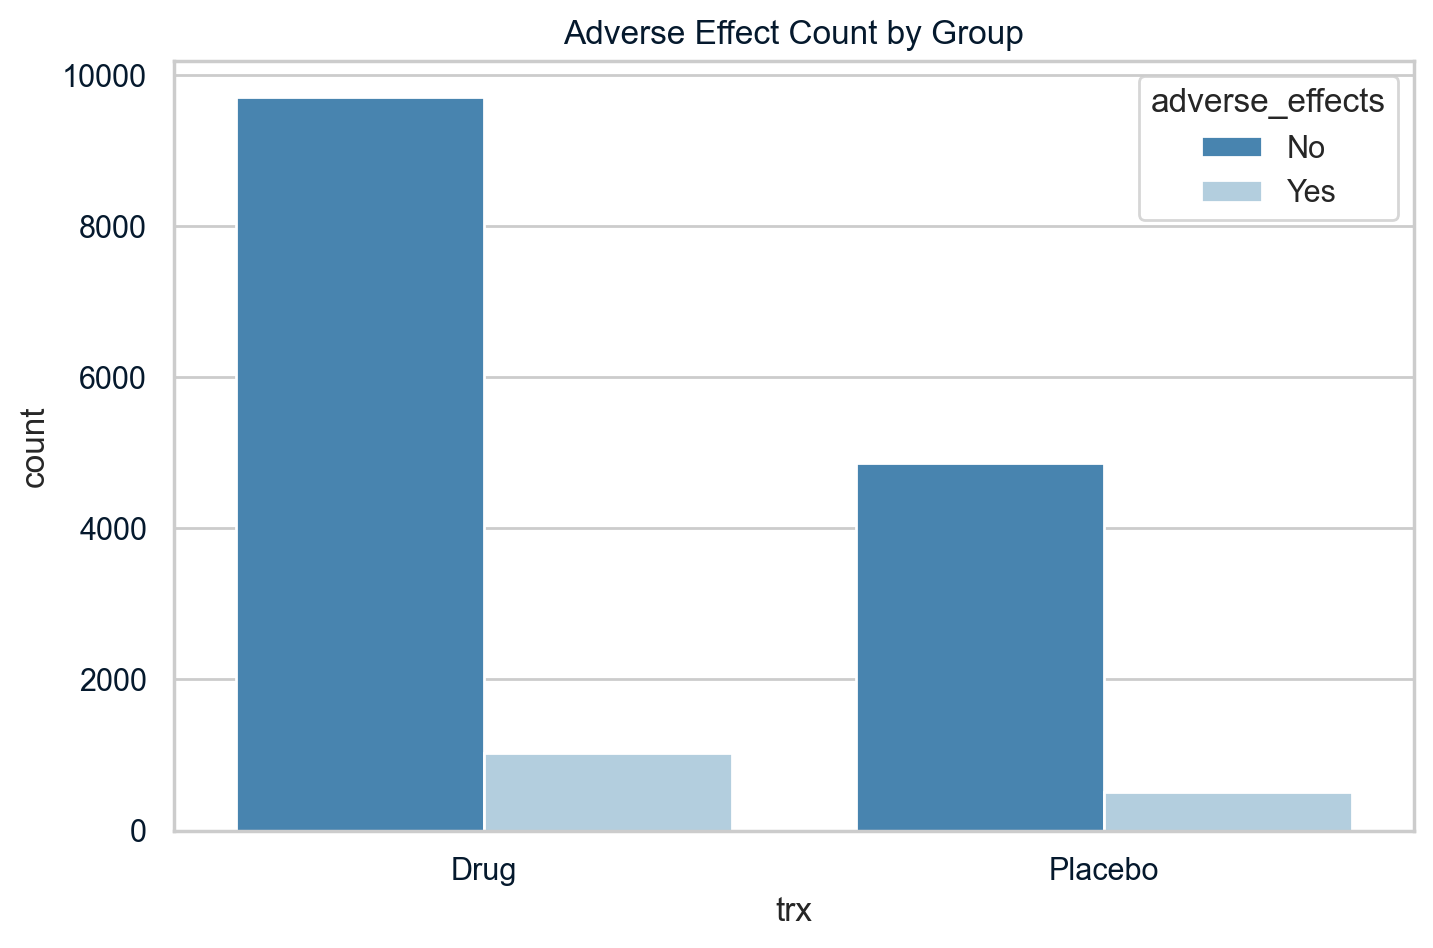

In [3]:
# Determine if the proportion of adverse effects differs significantly between the Drug and Placebo groups

total_rows_drug = (drug_safety['trx'] == 'Drug').sum()
total_rows_drug_adverse = ((drug_safety['trx'] == 'Drug') & (drug_safety['adverse_effects'] == 'Yes')).sum()

total_rows_placebo = (drug_safety['trx'] == 'Placebo').sum()
total_rows_placebo_adverse = ((drug_safety['trx'] == 'Placebo') & (drug_safety['adverse_effects'] == 'Yes')).sum()

# Number of adverse results in each group 
count = np.array([total_rows_drug_adverse, total_rows_placebo_adverse])

# Total number of observations in each group 
nobs = np.array([total_rows_drug, total_rows_placebo])

# Perform the two-sample z-test
stat, two_sample_p_value = proportions_ztest(count, nobs)

print(f"P-value: {two_sample_p_value:.4f}")

# Interpret the result
alpha = 0.1
if two_sample_p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference between the groups.")
else:
    print("Fail to reject the null hypothesis: There is no significant difference.")

# Visualize with Seaborn
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Using countplot (Seaborn's histogram equivalent for categorical data)
sns.countplot(data=drug_safety, x="trx", hue="adverse_effects", palette="Blues_r")
plt.title("Adverse Effect Count by Group")
plt.show()


In [4]:
# Find out if the number of adverse effects is independent of the treatment and control groups

from scipy.stats import chi2_contingency

observed = pd.crosstab(drug_safety['trx'], drug_safety['num_effects'])

# Chi-Square test
chi2_stat, num_effects_p_value, dof, expected_frequencies = chi2_contingency(observed)

# 3. Print the results
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"num_effects_p_value:  {num_effects_p_value:.4f}")
print(f"Degrees of Freedom:   {dof}")
print("\nExpected Frequencies Table:")
print(expected_frequencies)

# Interpret the result
alpha = 0.1
if num_effects_p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference between the groups.")
else:
    print("Fail to reject the null hypothesis: The number of adverse effects is independent of the groups.")

# Using pingouin
import pingouin
expected, observed, stats = pingouin.chi2_independence(data=drug_safety, x="num_effects", y="trx")
print(stats)

num_effects_p_value = stats['pval'][0]
print(num_effects_p_value)



Chi-Square Statistic: 1.7996
num_effects_p_value:  0.6150
Degrees of Freedom:   3

Expected Frequencies Table:
[[9.70379488e+03 9.60587096e+02 5.86211265e+01 3.99689499e+00]
 [4.86320512e+03 4.81412904e+02 2.93788735e+01 2.00310501e+00]]
Fail to reject the null hypothesis: The number of adverse effects is independent of the groups.
                 test    lambda      chi2  dof      pval    cramer     power
0             pearson  1.000000  1.799644  3.0  0.615012  0.010572  0.176275
1        cressie-read  0.666667  1.836006  3.0  0.607131  0.010678  0.179153
2      log-likelihood  0.000000  1.922495  3.0  0.588648  0.010926  0.186033
3       freeman-tukey -0.500000  2.001752  3.0  0.572043  0.011149  0.192379
4  mod-log-likelihood -1.000000  2.096158  3.0  0.552690  0.011409  0.199984
5              neyman -2.000000  2.344303  3.0  0.504087  0.012066  0.220189
0.6150123339426765


U Statistic: 29149339.5
P-value: 0.25696267004066287
Fail to reject the null hypothesis: There is no significant difference.


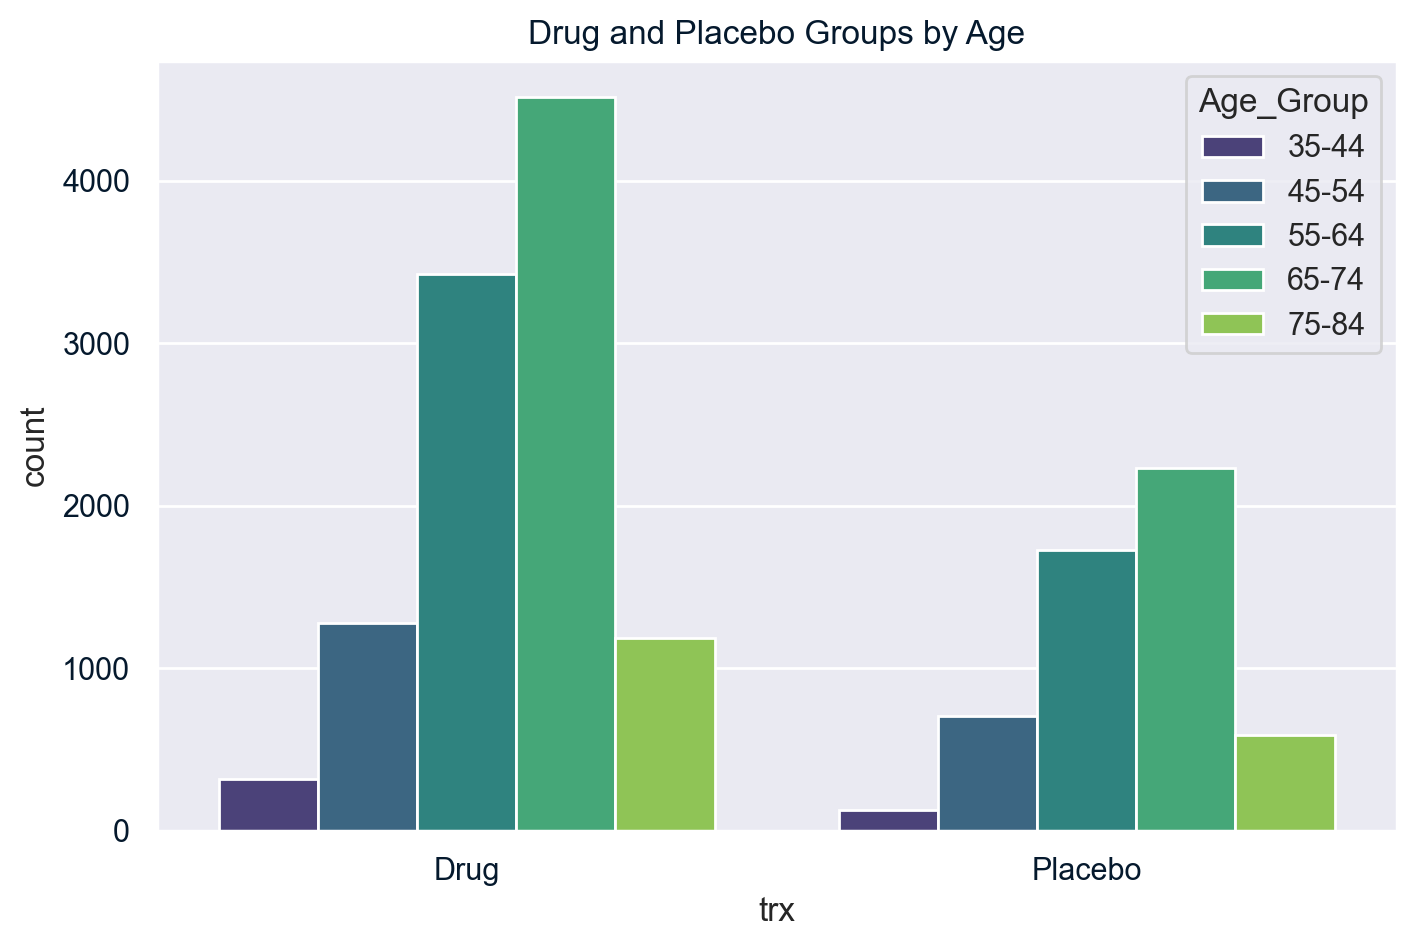

In [5]:
# Examine if there is a significant difference between the ages of the Drug and Placebo groups,

import scipy.stats as stats

group_a = drug_safety.loc[drug_safety['trx'] == 'Drug', 'age']
group_b = drug_safety.loc[drug_safety['trx'] == 'Placebo', 'age']

# Perform the Mann-Whitney U test
u_statistic, age_group_effects_p_value = stats.mannwhitneyu(group_a, group_b, alternative='two-sided')

print(f"U Statistic: {u_statistic}")
print(f"P-value: {age_group_effects_p_value}")

# Interpret the result
alpha = 0.05
if age_group_effects_p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference between the groups.")
else:
    print("Fail to reject the null hypothesis: There is no significant difference.")

# Define age bin edges and the labels for those categories
bins = [35, 45, 55, 65, 75, 85]
labels = ['35-44', '45-54', '55-64', '65-74', '75-84']

# Convert continuous Age into Categorical ranges
drug_safety['Age_Group'] = pd.cut(drug_safety['age'], bins=bins, labels=labels, right=False)

# Visualize with Seaborn
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 5))

# Using countplot (Seaborn's histogram equivalent for categorical data)
sns.countplot(data=drug_safety, x='trx', hue="Age_Group", palette='viridis')
plt.title("Drug and Placebo Groups by Age")
plt.show()
